In [15]:
!pip install netcdf4

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com


In [16]:
import netCDF4
file2read = netCDF4.Dataset("tomo_slice_8m_HV.nc")
print(file2read)
print(file2read.variables)

<class 'netCDF4._netCDF4.Dataset'>
root group (NETCDF4_CLASSIC data model, file format HDF5):
    dimensions(sizes): GroundRangeDim(1306), CrossRangeDim(13530), SigmaImageSingleLookRealPartGr(1306), SigmaImageSingleLookRealPartCr(13530), SigmaImageSingleLookImagPartGr(1306), SigmaImageSingleLookImagPartCr(13530)
    variables(dimensions): float32 GroundRange(GroundRangeDim), float32 CrossRange(CrossRangeDim), float32 SigmaImageSingleLookRealPart(SigmaImageSingleLookRealPartCr, SigmaImageSingleLookRealPartGr), float32 SigmaImageSingleLookImagPart(SigmaImageSingleLookImagPartCr, SigmaImageSingleLookImagPartGr), float32 MonostaticFlag(), float32 lambda()
    groups: 
{'GroundRange': <class 'netCDF4._netCDF4.Variable'>
float32 GroundRange(GroundRangeDim)
unlimited dimensions: 
current shape = (1306,)
filling on, default _FillValue of 9.969209968386869e+36 used, 'CrossRange': <class 'netCDF4._netCDF4.Variable'>
float32 CrossRange(CrossRangeDim)
unlimited dimensions: 
current shape = (13530,

In [19]:
array = file2read["SigmaImageSingleLookRealPart"][:]
array.min(), array.max()
#array = (array - array.min()) / (array.max() - array.min())
array = (array - array.mean()) / array.std()
array.min(), array.max()

(-20.52289, 23.827303)

In [9]:
array.reshape(-1);

masked_array(data=[0.0, 0.0, 0.0, ..., 0.0, 0.0, 0.0],
             mask=[False, False, False, ..., False, False, False],
       fill_value=1e+20,
            dtype=float32)

(array([1.7662519e+07, 6.8990000e+03, 6.0400000e+02, 9.9000000e+01,
        3.1000000e+01, 1.6000000e+01, 3.0000000e+00, 4.0000000e+00,
        3.0000000e+00, 2.0000000e+00]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ],
       dtype=float32),
 <BarContainer object of 10 artists>)

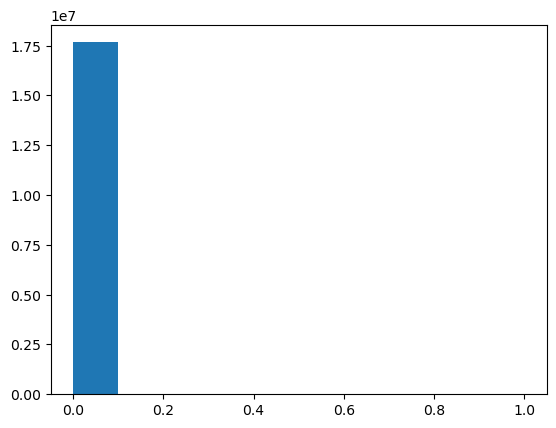

In [11]:
import matplotlib.pyplot as plt
plt.hist(array.reshape(-1))

<ipython-input-4-824380aa90b2>:3: RuntimeWarning: divide by zero encountered in log10
  amp_log = 10 * np.log10(np.absolute(array[0,:]))
/opt/anaconda/envs/orange_env/lib/python3.8/site-packages/numpy/lib/function_base.py:4737: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


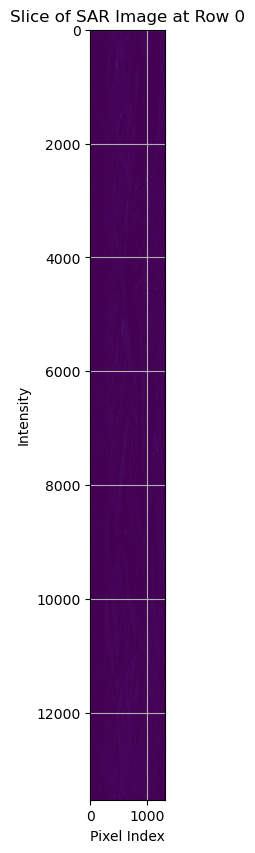

In [4]:
%matplotlib inline
import numpy as np
amp_log = 10 * np.log10(np.absolute(array[0,:]))
# computation of image percentiles for linear image stretching
p02, p98 = np.percentile(amp_log, (2, 98))

import matplotlib.pyplot as plt
# Plot the SAR image slice
plt.figure(figsize=(10, 10))
plt.imshow(array)
#self.ax2.imshow(np.absolute(self.phase_stack[:, :, h]))
#self.ax3.imshow(np.absolute(self.kz_stack[:, :, h]))
plt.title(f'Slice of SAR Image at Row 0')
plt.xlabel('Pixel Index')
plt.ylabel('Intensity')
plt.grid(True)
plt.show()